# 5-3 相关性与因果

请选择 `Python (da-course)` 内核，从 `notebooks/` 打开。本课用 `tips.csv` 和 `penguins.csv` 练习 Pearson/Spearman 相关系数、相关矩阵，并亲手复现经典的**辛普森悖论**。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

读取两份公开历史教学数据。

In [2]:
tips = pd.read_csv("../data/public/tips.csv")
penguins = pd.read_csv("../data/public/penguins.csv")
print("tips:", tips.shape, "penguins:", penguins.shape)

tips: (244, 7) penguins: (344, 7)


## 1. Pearson 与 Spearman 相关系数

Pearson 衡量线性关系，对离群值更敏感；Spearman 基于排序（秩），衡量单调关系。

In [3]:
print("Pearson :", round(tips["total_bill"].corr(tips["tip"], method="pearson"), 4))
print("Spearman:", round(tips["total_bill"].corr(tips["tip"], method="spearman"), 4))

Pearson : 0.6757
Spearman: 0.679


查看三列数值变量的相关系数矩阵。

In [4]:
tips[["total_bill", "tip", "size"]].corr().round(3)

,total_bill,tip,size
total_bill,1.000,0.676,0.598
tip,0.676,1.000,0.489
size,0.598,0.489,1.000


## 2. 辛普森悖论：整体负相关，分组后全为正相关

去掉 `bill_length_mm` 和 `bill_depth_mm` 的缺失行后，分别观察整体相关与分物种相关。

In [5]:
p_clean = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm"]).copy()
print("整体 Pearson 相关系数：", round(p_clean["bill_length_mm"].corr(p_clean["bill_depth_mm"]), 4))
for sp, g in p_clean.groupby("species"):
    print(f"  {sp:10s}: {g['bill_length_mm'].corr(g['bill_depth_mm']):+.4f}")

整体 Pearson 相关系数： -0.2351
  Adelie    : +0.3915
  Chinstrap : +0.6535
  Gentoo    : +0.6434


画散点图，对比“不分组”与“按物种着色”看到的完全相反的趋势。

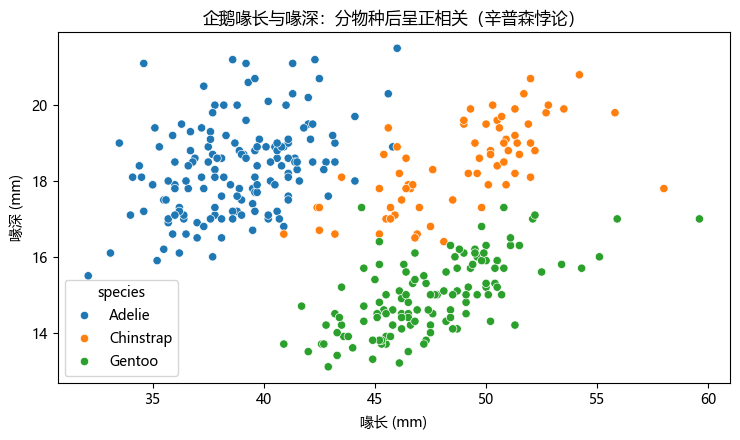

In [6]:
setup_chinese_font()
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.scatterplot(data=p_clean, x="bill_length_mm", y="bill_depth_mm", hue="species", ax=ax)
ax.set(title="企鹅喙长与喙深：分物种后呈正相关（辛普森悖论）", xlabel="喙长 (mm)", ylabel="喙深 (mm)")
fig.tight_layout()
plt.show()

## 练习 5-3.1 账单金额与小费的两种相关系数

计算 `tips` 中 `total_bill` 与 `tip` 的 Pearson 和 Spearman 相关系数，放入字典 `tips_corr`。

In [7]:
tips_corr = {
    "pearson": tips["total_bill"].corr(tips["tip"], method="pearson"),
    "spearman": tips["total_bill"].corr(tips["tip"], method="spearman"),
}
check("5-3.1", tips_corr)

True

## 练习 5-3.2 数值列相关系数矩阵

计算 `tips[["total_bill", "tip", "size"]]` 的 Pearson 相关系数矩阵（3×3 DataFrame）。

In [8]:
corr_matrix = tips[["total_bill", "tip", "size"]].corr()
check("5-3.2", corr_matrix)

True

## 练习 5-3.3 企鹅喙长与喙深的整体相关系数

对 `penguins` 去掉 `bill_length_mm` 与 `bill_depth_mm` 缺失行后，计算两列的整体 Pearson 相关系数。

In [9]:
p_sub = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm"])
overall_r = p_sub["bill_length_mm"].corr(p_sub["bill_depth_mm"])
check("5-3.3", overall_r)

True

## 练习 5-3.4 分物种计算相关系数

对去缺失后的企鹅数据按 `species` 分组，计算每个物种 `bill_length_mm` 与 `bill_depth_mm` 的 Pearson 相关系数，输出包含 `species`、`corr` 两列的 DataFrame，按 `species` 升序排列。

In [10]:
p_sub2 = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm"])
group_r = pd.DataFrame([
    {"species": sp, "corr": g["bill_length_mm"].corr(g["bill_depth_mm"])}
    for sp, g in p_sub2.groupby("species")
]).sort_values("species").reset_index(drop=True)
check("5-3.4", group_r)

True